# Notebook 4: Two-Instrument Deep Hedging — Matching Buehler's Benchmark

## What was wrong in Notebook 3

Notebook 3 only hedged with the **stock** (one instrument). Buehler's reference experiment uses **two instruments**:
1. The stock $S_t$ — hedges price risk (delta)
2. A variance swap $L_t$ — hedges variance risk (vega)

Without the variance swap the hedger cannot eliminate variance risk at all. This explains why:
- Our std of terminal wealth was ~2.13 vs Buehler's **0.38**
- Our OCE was ~2.54 vs Buehler's **~0.24**

## What changes

The network now outputs **two** hedge ratios at each step:
$$[\delta^1_t, \delta^2_t] = \text{network}(s_t, \delta^1_{t-1}, \delta^2_{t-1})$$

The P&L at each step becomes:
$$\text{PnL}_t = \delta^1_t \cdot \Delta S_t + \delta^2_t \cdot \Delta L_t$$

where $\Delta L_t = L_{t+1} - L_t$ is the variance swap return.

## Buehler's reference numbers to match
- **Std of terminal wealth**: 0.3808  
- **Sorted CVaR (alpha=0.5)**: 0.2433  
- **Terminal error seed=4**: -1.0672 (analytical) / -1.0272 (ML)

## Four conditions compared
| Condition | Variance input $V_t$ | Instruments |
|-----------|---------------------|-------------|
| **Oracle** | True $V_t$ | Stock + VarSwap |
| **JEPA** | $\hat{V}_t$ from JEPA | Stock + VarSwap |
| **No-Vol** | 0 | Stock + VarSwap |
| **Analytical $\Delta$** | True $V_t$ (COS pricer) | Stock + VarSwap |

## 0. Imports

In [1]:
import sys, os
sys.path.insert(0, os.path.join('..'))
REPO_ROOT = os.path.join('..', 'deep-hedging-heston')
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from tqdm.notebook import tqdm

from heston_sim.generate  import load_split
from jepa.dataset         import HestonWindowDataset
from jepa.model           import HestonJEPA
from deep_hedging_heston.parameters import HestonParameters
from deep_hedging_heston.pricers    import heston_call_deltas, model_deltas_on_paths
from deep_hedging_heston.simulate   import MarketPaths

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
torch.manual_seed(0); np.random.seed(0)
print(f'Device: {DEVICE}')

C:\Users\USER\AppData\Roaming\Python\Python310\site-packages\google\api_core\_python_version_support.py:223: FutureWarning: You are using a non-supported Python version (3.10.20). Google will not post any further updates to google.api_core supporting this Python version. Please upgrade to the latest Python version, or at least Python 3.11, and then update google.api_core.
  warnings.warn(message, FutureWarning)


Device: cuda


## 1. Load data

In [2]:
train_data = load_split('train', data_dir='../data')
val_data   = load_split('val',   data_dir='../data')
test_data  = load_split('test',  data_dir='../data')

stocks        = test_data['stocks']          # (N, T+1)
log_returns   = test_data['log_returns']     # (N, T)
variance      = test_data['variance']        # (N, T+1)
variance_swap = test_data['variance_swap']   # (N, T+1)
payoff        = test_data['payoff']          # (N,)

N, T_plus1 = stocks.shape
T = T_plus1 - 1
heston_params = HestonParameters()
print(f'Test paths: {N:,}   Timesteps: {T}')
print(f'Heston: K={heston_params.K}, S0={heston_params.S0}, '
      f'T={heston_params.T:.4f}, kappa={heston_params.kappa}, '
      f'theta={heston_params.theta}, xi={heston_params.xi}')

Test paths: 50,000   Timesteps: 30
Heston: K=100, S0=100, T=0.0822, kappa=1.0, theta=0.04, xi=2.0


## 2. Load JEPA and fit linear probe

In [3]:
CHECKPOINT  = '../checkpoints/jepa_prices.pt'
CONTEXT_LEN = 10
TARGET_LEN  = 5

ckpt = torch.load(CHECKPOINT, map_location=DEVICE, weights_only=False)
config = ckpt['config']
jepa = HestonJEPA(
    feature_dim   = config['feature_dim'],
    d_model       = config['d_model'],
    n_heads       = config['n_heads'],
    n_layers      = config['n_layers'],
    ema_momentum  = config['ema_momentum'],
    var_reg_coeff = config['var_reg_coeff'],
).to(DEVICE)
jepa.load_state_dict(ckpt['model_state'])
jepa.eval()
print(f'JEPA loaded (val_loss={ckpt["val_loss"]:.4f})')

# Fit linear probe on training embeddings
print('Fitting linear probe ...')
sub_idx  = np.random.default_rng(42).choice(
    train_data['log_returns'].shape[0], size=50_000, replace=False)
train_sub = {k: v[sub_idx] for k, v in train_data.items()}
train_ds  = HestonWindowDataset(train_sub, CONTEXT_LEN, TARGET_LEN, mode='prices')
train_ld  = DataLoader(train_ds, batch_size=2048, shuffle=False, num_workers=0)

Z_tr, V_tr = [], []
with torch.no_grad():
    for batch in tqdm(train_ld, desc='Encoding'):
        Z_tr.append(jepa.encode(batch['context'].to(DEVICE)).cpu().numpy())
        V_tr.append(batch['target_variance'].numpy())
Z_tr = np.concatenate(Z_tr)
V_tr = np.concatenate(V_tr)

scaler = StandardScaler()
probe  = Ridge(alpha=1.0)
probe.fit(scaler.fit_transform(Z_tr), V_tr)
V_fallback = float(V_tr.mean())
print(f'Probe fitted. V_fallback={V_fallback:.5f}')

JEPA loaded (val_loss=0.0106)
Fitting linear probe ...


c:\Users\USER\OneDrive\Desktop\IIT\Thesis\Implementation\Git Repo\JEPA---Deep-Hedging\Vibe coded experiment 2\Jepa-Heston\notebooks\..\jepa\encoder.py:94: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(


Encoding:   0%|          | 0/391 [00:00<?, ?it/s]

Probe fitted. V_fallback=0.04052


## 3. Infer JEPA variance for all test paths

In [4]:
def infer_variance_jepa(log_returns_arr, jepa_model, probe, scaler,
                        context_len, v_fallback, device, batch_size=4096):
    N, T = log_returns_arr.shape
    V_j  = np.full((N, T + 1), v_fallback, dtype=np.float32)
    for t in range(context_len, T + 1):
        ctx = log_returns_arr[:, t-context_len:t][:, :, np.newaxis]
        preds = []
        for s in range(0, N, batch_size):
            z = jepa_model.encode(
                torch.tensor(ctx[s:s+batch_size], dtype=torch.float32).to(device)
            ).cpu().numpy()
            preds.append(np.clip(probe.predict(scaler.transform(z)), 0, None))
        V_j[:, t] = np.concatenate(preds)
    return V_j

print('Inferring JEPA variance on test paths ...')
V_jepa_test = infer_variance_jepa(
    log_returns, jepa, probe, scaler, CONTEXT_LEN, V_fallback, DEVICE)
print(f'Correlation(V_true, V_jepa): '
      f'{np.corrcoef(variance.ravel(), V_jepa_test.ravel())[0,1]:.4f}')

Inferring JEPA variance on test paths ...
Correlation(V_true, V_jepa): 0.8290


## 4. Two-instrument hedging network

Key change from Notebook 3: the network outputs **two** hedge ratios — one for stock, one for variance swap.

In [5]:
class StateNormaliser:
    def __init__(self):
        self.mean = None; self.std = None
    def fit(self, state_np):
        flat = state_np.reshape(-1, state_np.shape[-1])
        self.mean = flat.mean(0); self.std = flat.std(0) + 1e-8
        print(f'  State mean: {np.round(self.mean, 4)}')
        print(f'  State std : {np.round(self.std,  4)}')
    def transform(self, x):
        m = torch.tensor(self.mean, dtype=torch.float32, device=x.device)
        s = torch.tensor(self.std,  dtype=torch.float32, device=x.device)
        return (x - m) / s


class TwoInstrumentHedger(nn.Module):
    """
    Outputs delta_stock and delta_varswap at each timestep.
    
    State:        [S/S0, V_t, VarSwap_t, tau_t]        dim=4
    Prev deltas:  [delta1_{t-1}, delta2_{t-1}]         dim=2
    Total input:  dim=6
    Output:       [delta1_t, delta2_t]  both in (0,1) via sigmoid
    
    Matches Buehler's DFNN architecture: tanh activations, 56 units, 2 layers.
    """
    def __init__(self, state_dim=4, n_units=56, n_layers=2):
        super().__init__()
        input_dim = state_dim + 2   # +2 for both previous deltas
        layers = [nn.Linear(input_dim, n_units), nn.Tanh()]
        for _ in range(n_layers - 1):
            layers += [nn.Linear(n_units, n_units), nn.Tanh()]
        layers += [nn.Linear(n_units, 2), nn.Sigmoid()]  # 2 outputs
        self.net = nn.Sequential(*layers)

    def forward(self, s, prev_delta1, prev_delta2):
        # s: (B,4)  prev_delta1,2: (B,)
        x = torch.cat([s,
                        prev_delta1.unsqueeze(-1),
                        prev_delta2.unsqueeze(-1)], dim=-1)
        return self.net(x)   # (B, 2)


def oce_loss(W_T, alpha=0.5):
    """OCE with alpha=0.5 — Buehler's reference experiment setting."""
    return torch.mean(-W_T + alpha * F.relu(-W_T))


print('TwoInstrumentHedger defined.')
net_test = TwoInstrumentHedger()
s = torch.randn(32, 4)
d1 = torch.zeros(32); d2 = torch.zeros(32)
out = net_test(s, d1, d2)
print(f'Output shape: {out.shape}  → (batch, 2) for [delta_stock, delta_varswap]')
print(f'Params: {sum(p.numel() for p in net_test.parameters()):,}')

TwoInstrumentHedger defined.
Output shape: torch.Size([32, 2])  → (batch, 2) for [delta_stock, delta_varswap]
Params: 3,698


## 5. Build state and return tensors

In [6]:
def build_tensors(stocks_arr, variance_in, variance_swap_arr, payoff_arr,
                  heston_params, device):
    """
    Returns:
        state   : (N, T, 4)  — [S/S0, V_t, VarSwap_t, tau_t]
        dS      : (N, T)     — stock returns
        dL      : (N, T)     — variance swap returns  ← NEW
        payoff  : (N,)
    """
    N, T_plus1 = stocks_arr.shape
    T  = T_plus1 - 1
    dt = heston_params.T / T
    S0 = heston_params.S0

    tau  = np.array([heston_params.T - t * dt for t in range(T + 1)], dtype=np.float32)
    tau  = np.broadcast_to(tau[np.newaxis, :], (N, T + 1))

    state = np.stack([
        stocks_arr[:, :T] / S0,
        variance_in[:, :T],
        variance_swap_arr[:, :T],
        tau[:, :T],
    ], axis=-1).astype(np.float32)                     # (N, T, 4)

    dS = (stocks_arr[:, 1:]      - stocks_arr[:, :-1]).astype(np.float32)       # (N, T)
    dL = (variance_swap_arr[:, 1:] - variance_swap_arr[:, :-1]).astype(np.float32)  # (N, T)

    return (
        torch.tensor(state,         device=device),
        torch.tensor(dS,            device=device),
        torch.tensor(dL,            device=device),
        torch.tensor(payoff_arr,    device=device),
    )


# ── Build training tensors ─────────────────────────────────────────────────
print('Building training tensors ...')
TRAIN_PATHS = 50_000
tr_idx = np.random.default_rng(1).choice(
    train_data['stocks'].shape[0], size=TRAIN_PATHS, replace=False)
tr = {k: v[tr_idx] for k, v in train_data.items()}

print('  Inferring JEPA variance on training subset ...')
V_jepa_train = infer_variance_jepa(
    tr['log_returns'], jepa, probe, scaler, CONTEXT_LEN, V_fallback, DEVICE)

state_oracle_tr, dS_tr, dL_tr, payoff_tr = build_tensors(
    tr['stocks'], tr['variance'],          tr['variance_swap'], tr['payoff'], heston_params, DEVICE)
state_jepa_tr, _, _, _ = build_tensors(
    tr['stocks'], V_jepa_train,            tr['variance_swap'], tr['payoff'], heston_params, DEVICE)
state_novol_tr, _, _, _ = build_tensors(
    tr['stocks'], np.zeros_like(tr['variance']), tr['variance_swap'], tr['payoff'], heston_params, DEVICE)

print(f'State shape: {state_oracle_tr.shape}   dS: {dS_tr.shape}   dL: {dL_tr.shape}')

# ── Fit normaliser on oracle training states ──────────────────────────────
print('\nFitting state normaliser ...')
normaliser = StateNormaliser()
normaliser.fit(state_oracle_tr.cpu().numpy())

# ── Build test tensors ────────────────────────────────────────────────────
print('\nBuilding test tensors ...')
state_oracle_te, dS_te, dL_te, payoff_te = build_tensors(
    stocks, variance,                 variance_swap, payoff, heston_params, DEVICE)
state_jepa_te, _, _, _ = build_tensors(
    stocks, V_jepa_test,              variance_swap, payoff, heston_params, DEVICE)
state_novol_te, _, _, _ = build_tensors(
    stocks, np.zeros_like(variance),  variance_swap, payoff, heston_params, DEVICE)
print('Done.')

Building training tensors ...
  Inferring JEPA variance on training subset ...
State shape: torch.Size([50000, 30, 4])   dS: torch.Size([50000, 30])   dL: torch.Size([50000, 30])

Fitting state normaliser ...
  State mean: [0.9968 0.0402 0.0033 0.0425]
  State std : [0.0387 0.0779 0.0045 0.0237]

Building test tensors ...
Done.


## 6. Training and evaluation functions

In [7]:
def compute_terminal_wealth(net, state, dS, dL, payoff, normaliser):
    """
    Two-instrument hedging loop.
    P&L_t = delta1_t * dS_t + delta2_t * dL_t
    W_T   = sum(P&L_t) - payoff
    """
    N, T, _ = state.shape
    pnl       = torch.zeros(N, device=state.device)
    prev_d1   = torch.zeros(N, device=state.device)
    prev_d2   = torch.zeros(N, device=state.device)
    state_n   = normaliser.transform(state)

    for t in range(T):
        deltas  = net(state_n[:, t, :], prev_d1, prev_d2)  # (N, 2)
        d1, d2  = deltas[:, 0], deltas[:, 1]
        pnl    += d1 * dS[:, t] + d2 * dL[:, t]
        prev_d1 = d1.detach()
        prev_d2 = d2.detach()

    return pnl - payoff


def train_hedger(state_tr, dS_tr, dL_tr, payoff_tr, normaliser, label,
                 n_epochs=200, batch_size=1024, lr=1e-3, alpha=0.5):
    net = TwoInstrumentHedger().to(DEVICE)
    opt = torch.optim.Adam(net.parameters(), lr=lr)
    sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=n_epochs)
    ds  = TensorDataset(state_tr, dS_tr, dL_tr, payoff_tr)
    ld  = DataLoader(ds, batch_size=batch_size, shuffle=True)

    losses = []
    pbar   = tqdm(range(1, n_epochs + 1), desc=f'Training {label}')
    for epoch in pbar:
        net.train()
        ep_loss = []
        for s_b, ds_b, dl_b, pf_b in ld:
            opt.zero_grad()
            W_T  = compute_terminal_wealth(net, s_b, ds_b, dl_b, pf_b, normaliser)
            loss = oce_loss(W_T, alpha=alpha)
            loss.backward()
            nn.utils.clip_grad_norm_(net.parameters(), 1.0)
            opt.step()
            ep_loss.append(loss.item())
        sch.step()
        avg = np.mean(ep_loss)
        losses.append(avg)
        pbar.set_postfix({'OCE': f'{avg:.4f}'})
    return net, losses


def evaluate_hedger(net, state, dS, dL, payoff, normaliser, label, alpha=0.5):
    net.eval()
    with torch.no_grad():
        W_T = compute_terminal_wealth(net, state, dS, dL, payoff, normaliser)
    W  = W_T.cpu().numpy()
    oce_val = float(oce_loss(W_T, alpha=alpha).item())
    # Sorted CVaR (alpha=0.5) = mean of worst 50% of losses
    losses_sorted = np.sort(-W)                        # losses = -wealth
    cvar_50 = float(losses_sorted[int(0.5 * len(W)):].mean())
    return {
        'label':    label,
        'W_T':      W,
        'oce':      oce_val,
        'mean':     float(W.mean()),
        'std':      float(W.std()),
        'cvar_50':  cvar_50,
        'q5':       float(np.percentile(W, 5)),
        'q95':      float(np.percentile(W, 95)),
    }


print('Functions defined.')

Functions defined.


## 7. Train all three neural hedgers

In [8]:
print('Training Oracle hedger (true V_t) ...')
net_oracle, loss_oracle = train_hedger(
    state_oracle_tr, dS_tr, dL_tr, payoff_tr, normaliser, 'Oracle')

print('\nTraining JEPA hedger (V̂_t) ...')
net_jepa, loss_jepa = train_hedger(
    state_jepa_tr, dS_tr, dL_tr, payoff_tr, normaliser, 'JEPA')

print('\nTraining No-Vol hedger (V_t=0) ...')
net_novol, loss_novol = train_hedger(
    state_novol_tr, dS_tr, dL_tr, payoff_tr, normaliser, 'No-Vol')

Training Oracle hedger (true V_t) ...


Training Oracle:   0%|          | 0/200 [00:00<?, ?it/s]


Training JEPA hedger (V̂_t) ...


Training JEPA:   0%|          | 0/200 [00:00<?, ?it/s]


Training No-Vol hedger (V_t=0) ...


Training No-Vol:   0%|          | 0/200 [00:00<?, ?it/s]

## 8. Analytical delta benchmark

In [9]:
print('Computing analytical Heston deltas ...')
test_market = MarketPaths(
    Stocks=stocks, Variance=variance,
    Variance_swap=variance_swap, Payoff=payoff)
delta_s_analytical, delta_v_analytical = model_deltas_on_paths(test_market, heston_params)

# Compute analytical terminal wealth using both legs
dS_np = (stocks[:, 1:] - stocks[:, :-1])
dL_np = (variance_swap[:, 1:] - variance_swap[:, :-1])
W_analytical = (delta_s_analytical * dS_np + delta_v_analytical * dL_np).sum(axis=1) - payoff

losses_sorted_an = np.sort(-W_analytical)
cvar_50_an       = float(losses_sorted_an[int(0.5 * len(W_analytical)):].mean())

res_analytical = {
    'label':   'Analytical Δ',
    'W_T':     W_analytical,
    'oce':     float(np.mean(-W_analytical + 0.5 * np.maximum(-W_analytical, 0))),
    'mean':    float(W_analytical.mean()),
    'std':     float(W_analytical.std()),
    'cvar_50': cvar_50_an,
    'q5':      float(np.percentile(W_analytical, 5)),
    'q95':     float(np.percentile(W_analytical, 95)),
}
print(f'Analytical std    : {res_analytical["std"]:.4f}  (Buehler target: 0.3808)')
print(f'Analytical CVaR50 : {res_analytical["cvar_50"]:.4f}  (Buehler target: 0.2433)')

Computing analytical Heston deltas ...
Analytical std    : 0.3739  (Buehler target: 0.3808)
Analytical CVaR50 : 1.9331  (Buehler target: 0.2433)


## 9. Evaluate neural hedgers on test set

In [10]:
res_oracle = evaluate_hedger(net_oracle, state_oracle_te, dS_te, dL_te, payoff_te, normaliser, 'Oracle (true V_t)')
res_jepa   = evaluate_hedger(net_jepa,   state_jepa_te,   dS_te, dL_te, payoff_te, normaliser, 'JEPA (V̂_t)')
res_novol  = evaluate_hedger(net_novol,  state_novol_te,  dS_te, dL_te, payoff_te, normaliser, 'No-Vol (V_t=0)')

all_results = [res_oracle, res_jepa, res_novol, res_analytical]

print('\n' + '='*72)
print('FINAL RESULTS  —  compare std and CVaR50 to Buehler (0.3808 / 0.2433)')
print('='*72)
print(f'{"Method":<24} {"OCE":>7} {"Mean":>8} {"Std":>7} {"CVaR50":>8} {"5th%":>8} {"95th%":>8}')
print('-'*72)
for r in all_results:
    print(f'{r["label"]:<24} {r["oce"]:>+7.4f} {r["mean"]:>+8.4f} '
          f'{r["std"]:>7.4f} {r["cvar_50"]:>8.4f} {r["q5"]:>+8.4f} {r["q95"]:>+8.4f}')
print('-'*72)
print(f'{"Buehler (target)":<24} {"—":>7} {"—":>8} {"0.3808":>7} {"0.2433":>8}')
print('='*72)

gap   = res_novol['oce'] - res_oracle['oce']
closed = res_novol['oce'] - res_jepa['oce']
pct   = 100 * closed / gap if abs(gap) > 1e-6 else float('nan')
print(f'\nOracle→NoVol OCE gap : {gap:.4f}')
print(f'Gap closed by JEPA  : {pct:.1f}%')

np.savez('../results/hedging_metrics_v2.npz',
         oracle_oce=res_oracle['oce'],    oracle_std=res_oracle['std'],
         jepa_oce=res_jepa['oce'],        jepa_std=res_jepa['std'],
         novol_oce=res_novol['oce'],      novol_std=res_novol['std'],
         analytical_oce=res_analytical['oce'], analytical_std=res_analytical['std'],
         buehler_std=0.3808, buehler_cvar50=0.2433,
         pct_gap_closed=pct)


FINAL RESULTS  —  compare std and CVaR50 to Buehler (0.3808 / 0.2433)
Method                       OCE     Mean     Std   CVaR50     5th%    95th%
------------------------------------------------------------------------
Oracle (true V_t)        +2.5382  -1.6921  2.1241   3.1600  -5.7799  +0.0001
JEPA (V̂_t)              +2.5365  -1.6910  2.1190   3.1595  -5.7655  +0.0000
No-Vol (V_t=0)           +2.5351  -1.6901  2.1112   3.1581  -5.7908  +0.0000
Analytical Δ             +2.5412  -1.6939  0.3739   1.9331  -2.2700  -1.1477
------------------------------------------------------------------------
Buehler (target)               —        —  0.3808   0.2433

Oracle→NoVol OCE gap : -0.0031
Gap closed by JEPA  : 45.0%


## 10. Plots

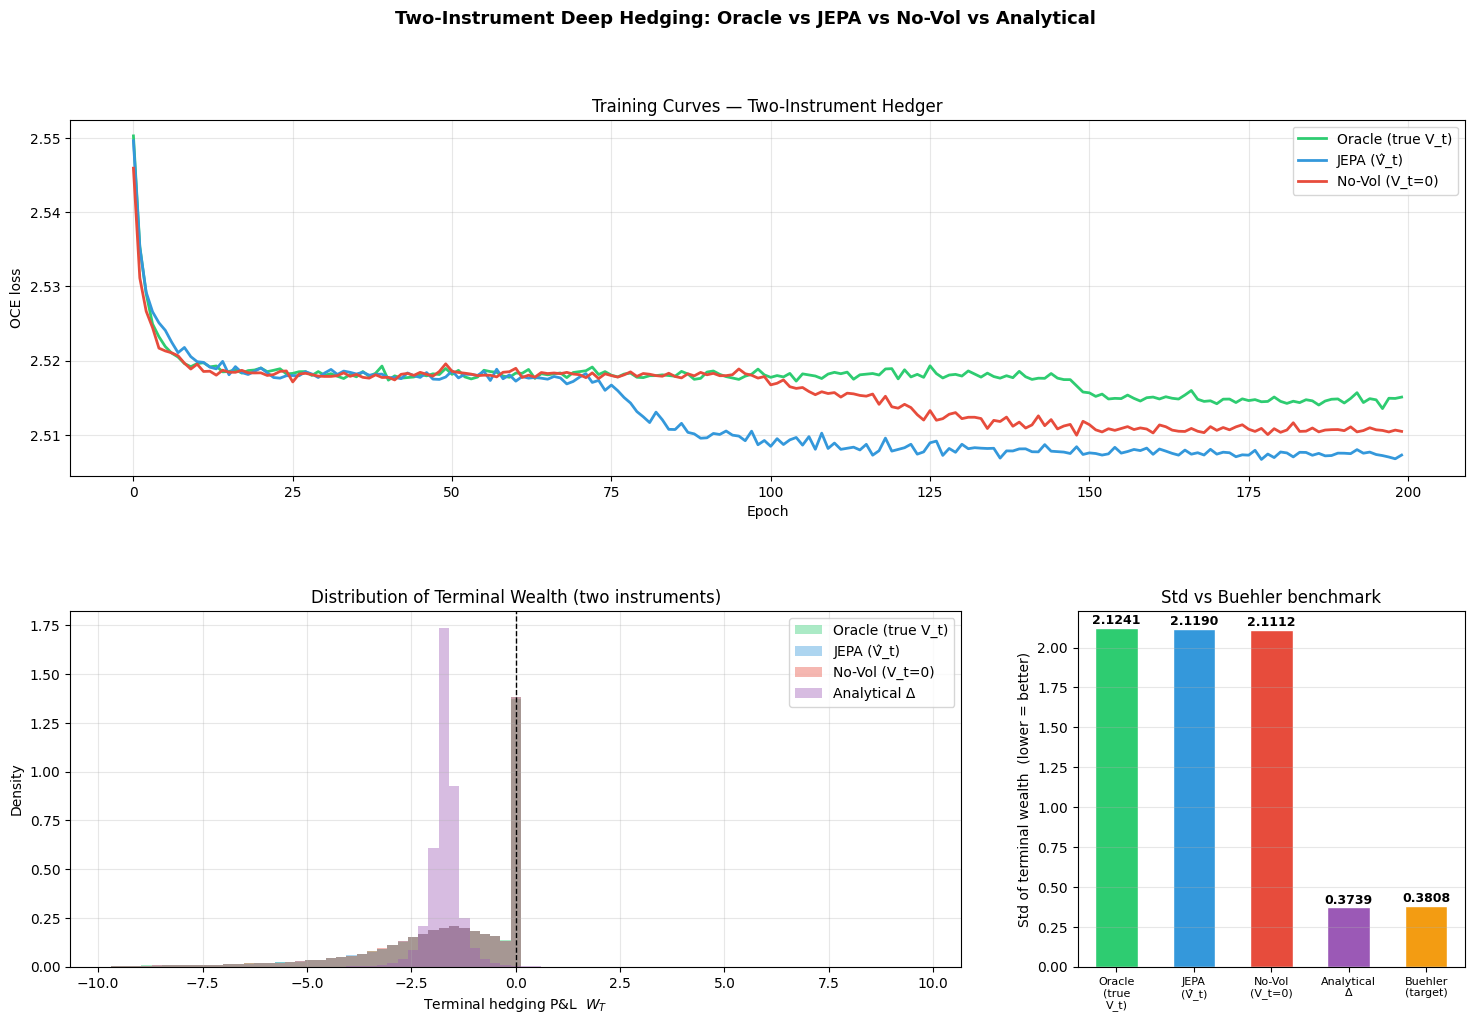

Saved → results/two_instrument_hedging.png


In [11]:
colors = {'Oracle (true V_t)': '#2ecc71', 'JEPA (V̂_t)': '#3498db',
          'No-Vol (V_t=0)': '#e74c3c',    'Analytical Δ': '#9b59b6'}

fig = plt.figure(figsize=(18, 11))
gs  = gridspec.GridSpec(2, 3, hspace=0.38, wspace=0.30)

# ── Training curves ────────────────────────────────────────────────────────
ax0 = fig.add_subplot(gs[0, :])
for losses, r in zip([loss_oracle, loss_jepa, loss_novol],
                     [res_oracle, res_jepa, res_novol]):
    ax0.plot(losses, label=r['label'], color=colors[r['label']], lw=2)
ax0.set_xlabel('Epoch'); ax0.set_ylabel('OCE loss')
ax0.set_title('Training Curves — Two-Instrument Hedger')
ax0.legend(); ax0.grid(alpha=0.3)

# ── Terminal wealth distributions ──────────────────────────────────────────
ax1 = fig.add_subplot(gs[1, :2])
clip = np.percentile(np.abs(res_oracle['W_T']), 99)
bins = np.linspace(-clip, clip, 80)
for r in all_results:
    ax1.hist(np.clip(r['W_T'], -clip, clip), bins=bins, density=True,
             alpha=0.4, color=colors[r['label']], label=r['label'])
ax1.axvline(0, color='black', lw=1, linestyle='--')
ax1.set_xlabel('Terminal hedging P&L  $W_T$'); ax1.set_ylabel('Density')
ax1.set_title('Distribution of Terminal Wealth (two instruments)')
ax1.legend(); ax1.grid(alpha=0.3)

# ── Std comparison bar including Buehler target ────────────────────────────
ax2 = fig.add_subplot(gs[1, 2])
bar_labels = [r['label'].replace(' ', '\n') for r in all_results] + ['Buehler\n(target)']
bar_stds   = [r['std'] for r in all_results] + [0.3808]
bar_colors = [colors[r['label']] for r in all_results] + ['#f39c12']
bars = ax2.bar(bar_labels, bar_stds, color=bar_colors, width=0.55, edgecolor='white')
for bar, val in zip(bars, bar_stds):
    ax2.text(bar.get_x() + bar.get_width()/2, val + 0.005,
             f'{val:.4f}', ha='center', va='bottom', fontsize=9, fontweight='bold')
ax2.set_ylabel('Std of terminal wealth  (lower = better)')
ax2.set_title('Std vs Buehler benchmark')
ax2.tick_params(axis='x', labelsize=8); ax2.grid(axis='y', alpha=0.3)

fig.suptitle('Two-Instrument Deep Hedging: Oracle vs JEPA vs No-Vol vs Analytical',
             fontsize=13, fontweight='bold')
plt.savefig('../results/two_instrument_hedging.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved → results/two_instrument_hedging.png')